# Исследование рынка стартапов по историческим данным

## Введение

Проект посвещен исследовательскому анализу стартапов. В нашем распоряжении данные с информацией о компаниях, объёмах и типах привлечённых инвестиций, а также с дополнительной статистикой по возвратам средств. Целью проекта является исследование структуры и динамики финансирования стартапов. Для достижения цели поставлены следующие задачи:
- Провести предобработку данных, убрать дубликаты и пропуски, проверить корректность числовых и временных значений.
- Выделить группы компаний по срокам финансирования и сравнить их по количеству и объёму инвестиций.
- Классифицировать сегменты рынка на массовые, средние и нишевые и учесть это в дальнейшем анализе.
- Определить типичные и аномальные значения объёмов финансирования, исключить выбросы и ограничить период исследования.
- Сравнить популярность и объёмы разных типов финансирования.
- Проанализировать динамику раундов и объёмов инвестиций по годам, а также изменения в массовых сегментах рынка.
- Рассчитать долю возврата средств для разных типов финансирования и оценить её устойчивость.
- Подвести итоговые выводы и дать рекомендации, куда и каким образом было бы целесообразно инвестировать, если бы на дворе был 2015 год.

## 1. Знакомство с данными: загрузка и предобработка

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.

### 1.1. Вывод общей информации

Загрузим необходимые для работы библиотеки.

In [1]:
# для лучшей читаемости тетрадки
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
pd.set_option('display.max_columns', None)

import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
import matplotlib.colors as mcolors

import seaborn as sns

import phik
    
import numpy as np

In [3]:
# Зададим функцию для первичного анализа датасета

def init_analysis(df, df_name):
    """
    Эта функция автоматизирует шаги первичного анализа датасета:
    1) Выводит первые пять строк датасета
    2) Выводит общую инфромацию о датасете
    3) Выводит асболютное и относитльное кол-во пропусков в столбцах датасета
    4) Выводит статистики количественных столбцов датасета
    5) Считает уникальные значения строковых столбцов датасета
    6) Считает дублированные строки датасета
    
    Как пользоваться: у функции два параметра: датасет df - объект pandas.DataFrame,
    и название датасета df_name в виде строки
    """
    print(f'Выведем первые пять строк датасета {df_name}:')
    display(df.head())
    print('\n')
    
    print(f'Выведем общую информацию о датасете {df_name}:')
    df.info()
    print('\n')
    
    nans = pd.concat([df.isna().sum(), df.isna().sum()/df.shape[0]], axis=1)
    nans.columns = ['NANs_count', 'NANs_share']
    print(f'Выведем абсолютное и относительное кол-во пропусков в столбцах датасета {df_name}:')
    print(nans, end='\n\n')
    
    quantitative_cols_series = (df.dtypes.astype(str).str.contains('float') | df.dtypes.astype(str).str.contains('int'))
    quantitative_cols_list = quantitative_cols_series.loc[quantitative_cols_series == True].index.tolist()
    
    for col in quantitative_cols_list:
        print(f'Статистика столбца {col}:')
        print(df[col].describe(), end='\n\n')
        
    categorical_cols_series = df.dtypes.astype(str).str.contains('object')
    categorical_cols_list = categorical_cols_series.loc[categorical_cols_series == True].index.tolist()
    
    for col in categorical_cols_list:
        print(f'Уникальные количество уникальных значений столбца {col}:')
        print(df[col].nunique(), end='\n\n')
        
    print('Выведем количество дублированных строк:')
    print(df.duplicated().sum())

In [4]:
# прочитаем датасеты cb_investments.csv и cb_returns.csv
investments_df = pd.read_csv("datasets/cb_investments.zip", sep=';', low_memory=False)
returns_df = pd.read_csv("datasets/cb_returns.csv", low_memory=False)

#### Знакомство с `cb_investments.csv`

In [5]:
# Выведем первые пять строк датасета cb_investments.csv
display(investments_df.head())

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,1.0,NaN,1636-09-08,NaN,NaN,1636.0,2014-01-06,NaN,2014-01-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,90000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,1.0,NaN,1785-01-01,NaN,NaN,1785.0,2014-05-15,NaN,2014-05-15,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,1.0,1.0,1802-07-19,NaN,NaN,1802.0,2009-07-02,2009-07-02,2009-07-02,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,3.0,0.0,1817-01-01,NaN,NaN,1817.0,2013-11-21,2013-11-21,2014-11-03,0.0,0.0,0.0,1600000.0,0.0,0.0,0.0,6100000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,1.0,NaN,1826-01-01,NaN,NaN,1826.0,2014-01-14,NaN,2014-01-14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,540000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Первые пять строчек датасета не содержат информации в столбцах `founded_month` и `founded_quarter`. Отсортируем датасет по дате основания в порядке убывания, чтобы посмотреть, в каком формате записаны значения в этих столбцах.

In [6]:
# выведем первые пять строк датасета cb_investments.csv, отсортированного по дате основания в порядке убывания.
display(investments_df.sort_values('founded_at', ascending=False).head())

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
38553,ChangeAgain.Me,http://changeagain.me,|User Experience Design|Sales and Marketing|,Sales and Marketing,"20,000",operating,NaN,NaN,NaN,NaN,1.0,NaN,2014-12-13,2014-12,2014-Q4,2014.0,2014-08-01,NaN,2014-08-01,0.0,0.0,0.0,20000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
38552,Le Herbé,https://leherbe.com,|Medical Marijuana Patients|Organic Food|Produ...,Product Design,"1,00,000",operating,USA,WA,Seattle,Seattle,1.0,NaN,2014-12-01,2014-12,2014-Q4,2014.0,2014-12-01,NaN,2014-12-01,0.0,0.0,0.0,100000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
38551,Manifatto,http://manifatto.com,|E-Commerce|,E-Commerce,"30,000",operating,NaN,NaN,NaN,NaN,1.0,NaN,2014-11-26,2014-11,2014-Q4,2014.0,2014-09-24,NaN,2014-09-24,30000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
38550,"RDFY, Inc.",https://www.rdfy.me,|Retail Technology|,Retail Technology,-,operating,USA,NY,New York City,New York,1.0,NaN,2014-11-21,2014-11,2014-Q4,2014.0,2014-12-01,NaN,2014-12-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
38549,Kandid,http://kandid.co,|Apps|,Apps,"14,00,000",operating,USA,CA,SF Bay Area,San Francisco,1.0,NaN,2014-11-19,2014-11,2014-Q4,2014.0,2014-12-02,NaN,2014-12-02,1400000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Выведем последние строки датасета `cb_investments.csv`.

In [7]:
investments_df.tail()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
54289,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54290,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54291,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54292,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Датасет `cb_investments.csv` содержат полностью пустые строки. Выведем общую инфромацию о датасете `cb_investments.csv`.

In [8]:
investments_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

Сохраним данные о датасете до предобработки для сравнения с результирующим датасетом после предобработки.

In [9]:
# Сохраним количество строк и столбцов в датасете cb_invstments.csv до предобработки
init_investments_shape = investments_df.shape

In [10]:
# Сохраним количество пропусков и долю пропусков в столбцах датасета cb_investments.csv 
init_investments_nans = investments_df.isna().agg(['sum', 'mean'])

Датасет `cb_investments.csv` содержит 40 столбцов и 54293 строк с информацией о общей информацией о стартапах и об их финансировании.
Первичный анализ данных позволил сделать следующие выводы:
- Названия столбцов нужно привести к одному типу, например, snake_case (названия, состоящие из нескольких слов, разделяются символом нижнего подчеркивания `_`, все символы переводятся в нижний регистр) + нужно удалить пробелы в начале названий столбцов (встречаются в двух столбцах);
- Столбцы содержат следующие типы данных:
    - данные типа `object`. Тип `object` предназначен для хранения различных объектов различных типов, в частности, позволяет хранить строки. Для части столбцов тип данных подобран верно. Столбцы `founded_at`, `founded_month`, `founded_quarter`, `first_funding_at`, `mid_funding_at` и `last_funding_at` содержат информацию о датах разных событий, связанных со стартапом: эти столбцы нужно перевести в формат `datetime` для дальнейшей группировки и фильтрации по датам. Столбец `funding_total_usd`содержит информацию о сумме инвестиций - нужно перевести данные в числовой формат, перед этим удалив из строковых значений запятые, выделяющие разряды числа.
    - данные типа `float64`. Значения в столбцах соответствуют типу данных, при этом для оптимизации памяти нужно произвести понижение разрядности.
- Пропуски содержатся во всех столбцах. Кроме явных пропусков нужно проверить значения-индикаторы, говорящие об обсутствии данных. В данных присутствуют полностью пустые строчки.
- Судя по первому знакомству с данными, значения в столбцах соответствуют их описанию.

#### Знакомство с `cb_returns.csv`

In [11]:
# Выведем первые пять строк датасета cb_returns.csv
returns_df.head()

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
3,2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
4,2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


In [12]:
# Выведем общую информацию о cb_returns.csv
returns_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


Датасет `cb_returns.csv` содержит 14 столбцов и 15 строк с информацией о суммах возврата финансирования.
Первичный анализ данных позволил сделать следующие выводы:
- Названия столбцов исполнены в удобном формате snake_case;
- Столбцы содержат следующие типы данных:
    - данные типа `int64` содержатся в столбце `year` с информацией о годе возврата финансирования. Тип подходит для данных в столбце, однако для оптимизации памяти нужно понизить разрядность данных;
    - данные типа `float64` содержатся во всех остальных столбцах. В этих столбцах содержится информация о сумме возврата инвестиций в миллионах долларов - тип данных с правающей запятой подходит для хранения таких данных. Однако для оптимизации данных нужно провести понижение разрядности.
- Судя по первому знакомству с данными, значения в столбцах соответствуют их описанию.

#### Промежуточный вывод

- Датасет `cb_investments.csv` содержит 40 столбцов и 54293 строк с информацией о общей информацией о стартапах и об их финансировании. Названия столбцов нужно привести к типу ***snake_case***. Столбцы датасета содержат данные типов `object` и `float64`. Даны рекомендации по преобразованию типов данных: столбцы `founded_at`, `founded_month`, `founded_quarter`, `first_funding_at`, `mid_funding_at` и `last_funding_at` перевести в формат `datetime`; столбец `funding_total_usd` перевести в формат `int` с подбором оптимальной разрядности данных; для столбцов со значениями `float64` произвести понижение разрядности данных. Пропуски содержатся во всех столбцах. Кроме явных пропусков нужно проверить значения-индикаторы. В данных присутствуют полностью пустые строчки. Судя по первому знакомству с данными, значения в столбцах соответствуют их описанию.

- Датасет `cb_returns.csv` содержит 14 столбцов и 15 строк с информацией о суммах возврата финансирования. Столбцы содержат данные типов `int64` и `float64`. Даны рекомендации по предобработке: понизить разрядность данных. Судя по первому знакомству с данными, значения в столбцах соответствуют их описанию.

Перейдем к предобработке данных.

### 1.2. Предобработка данных

#### Предобработка `cb_investments.csv`

Приведем названия столбцов в `cb_investments.csv` к стилю ***snakecase***.

In [13]:
# Приведем названия столбцов в cb_investments.csv к стилю snakecase.
investments_df.columns = investments_df.columns.str.lower().str.strip()

In [14]:
#Выведем новые названия столбцов для проверки
investments_df.columns

Index(['name', 'homepage_url', 'category_list', 'market', 'funding_total_usd',
       'status', 'country_code', 'state_code', 'region', 'city',
       'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_a', 'round_b',
       'round_c', 'round_d', 'round_e', 'round_f', 'round_g', 'round_h'],
      dtype='object')

Уберем в столбце `funding_total_usd` выделение разрядов, приведем его к числовому типу и избавимся от строк с нулевым значением.

In [15]:
#Удалим запятые, разделяющие числа на разряды, из столбца funding_total_usd
investments_df['funding_total_usd'] = investments_df['funding_total_usd'].str.replace(',', '').str.strip()

In [16]:
# Проверим, какие значения встречаются в столбце funding_total_usd
investments_df['funding_total_usd'].value_counts()

funding_total_usd
-           8531
1000000      925
500000       761
100000       749
40000        680
            ... 
2224160        1
63276          1
16491811       1
892254         1
802452         1
Name: count, Length: 14617, dtype: int64

В `funding_total_usd` 8531 ячейки со значением **"-"**. В нашем распоряжении нет информации о том, чему соответствуют значения **"-"**, однако можно предположить, что в таком случае данные о финансировании отсутствуют. Эту гипотезу можно проверить, посчитав сумму по столбцам всех видов финансирования для строк, содержащих **"-"** в столбце `funding_total_usd`.

In [17]:
# составим список столбцов с информацией о фмнансировании 
funding_list = ['seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_a', 'round_b',
       'round_c', 'round_d', 'round_e', 'round_f', 'round_g', 'round_h']

In [18]:
# выведем все возможные суммы по столбцам с информацией о финансировании для строк, в которых в 'funding_total_usd' стоит значение '-'
investments_df.loc[investments_df['funding_total_usd'] == '-'][funding_list].sum(axis=1).value_counts()

0.0    8531
Name: count, dtype: int64

Просуммировав суммы инвестирования для строк со значениями **"-"** в столбце `funding_total_usd`, мы получили **0** для всех строк. В таком случае можно заменить безболезненно заменить значения **"-"** на **0**.

In [19]:
# напишем функцию для замены '-' на 0 в столбце funding_total_usd
def hyphen_to_zero(row):
    if row == '-':
        return 0
    else:
        return row

In [20]:
# заменим '-' на 0 в столбце funding_total_usd
investments_df['funding_total_usd'] = investments_df['funding_total_usd'].apply(hyphen_to_zero)

In [21]:
# выведем уникальные значения в столбце funding_total_usd для проверки
investments_df['funding_total_usd'].value_counts()

funding_total_usd
0           8531
1000000      925
500000       761
100000       749
40000        680
            ... 
2224160        1
63276          1
16491811       1
892254         1
802452         1
Name: count, Length: 14617, dtype: int64

In [22]:
# Посчитаем кол-во пропусков в funding_total_usd. Их необходимо удалить для перевода типа данных в integer
print(f"Пропусков в funding_total_usd: {investments_df['funding_total_usd'].isna().sum()}")

Пропусков в funding_total_usd: 4856


In [23]:
# удалим пропуски в funding_total_usd
investments_df.dropna(subset=['funding_total_usd'], inplace=True)

In [24]:
# Понизим разрядность данных в funding_total_usd
investments_df['funding_total_usd'] = pd.to_numeric(investments_df['funding_total_usd'], downcast='integer')

In [25]:
# удалим строки с нулевыми значениями в funding_total_usd
zeros_index = investments_df.loc[investments_df['funding_total_usd'] == 0]['funding_total_usd'].index
investments_df.drop(zeros_index, inplace=True)

Обработаем типы данных в столбцах, которые хранят значения даты и времени.

In [26]:
# Объявим список столбцов с данными о датах
datetime_list = ['founded_at', 'founded_month', 'founded_quarter',
                 'first_funding_at', 'mid_funding_at', 'last_funding_at']

In [27]:
# Подсчитаем количество пропущенных значений в столцбах с датами
missing_datetime_before = investments_df[datetime_list].isna().sum()

In [28]:
# Преобразуем столбцы в датами в формат datetime
investments_df['founded_at'] = pd.to_datetime(investments_df['founded_at'], errors='coerce')
investments_df['founded_month'] = pd.to_datetime(investments_df['founded_month'], format='%Y-%m', errors='coerce')
investments_df['founded_quarter'] = pd.to_datetime(investments_df['founded_quarter'], errors='coerce')
investments_df['first_funding_at'] = pd.to_datetime(investments_df['first_funding_at'], errors='coerce')
investments_df['mid_funding_at'] = pd.to_datetime(investments_df['mid_funding_at'], errors='coerce')
investments_df['last_funding_at'] = pd.to_datetime(investments_df['last_funding_at'], errors='coerce')

In [29]:
# Подсчитаем количество пропущенных значений в столцбах с датами после преобразования типов данных
missing_datetime_after = investments_df[datetime_list].isna().sum()

In [30]:
# Проверим, появились ли новые пропуски после преобразования данных в столбцах с датами 
missing_datetime_after - missing_datetime_before

founded_at          1
founded_month       0
founded_quarter     0
first_funding_at    2
mid_funding_at      0
last_funding_at     0
dtype: int64

В столбцах `funding_at` и `first_funding_at` после преобразования данных появились 1 и 2 пропусков соответственно.

Произведем понижение разрядности для столбцов `cb_investments.csv` с типом данных `float64`.

In [31]:
# сформируем список названий столбцов с данными float64
downcast_list = ['founded_year', 'funding_rounds', 'participants', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_a', 'round_b',
       'round_c', 'round_d', 'round_e', 'round_f', 'round_g', 'round_h']

In [32]:
# проведем понижение разрядности данных в столбцах cb_investments.csv с данными float64
for column in downcast_list:
    investments_df[column] = pd.to_numeric(investments_df[column], downcast='float')

In [33]:
# проверим типы данных после понижения разрядности
investments_df[downcast_list].dtypes

founded_year            float32
funding_rounds          float32
participants            float32
seed                    float64
venture                 float64
equity_crowdfunding     float32
undisclosed             float64
convertible_note        float32
debt_financing          float64
angel                   float64
grant                   float64
private_equity          float64
post_ipo_equity         float64
post_ipo_debt           float64
secondary_market        float64
product_crowdfunding    float32
round_a                 float64
round_b                 float64
round_c                 float64
round_d                 float64
round_e                 float64
round_f                 float64
round_g                 float64
round_h                 float32
dtype: object

Обработаем текстовые данные. Пропуски в текстовых столбцах заполним заглушками там, где это понадобится.

In [34]:
# сформируем список названий столбцов с текстовыми данными
str_col_list = ['name', 'homepage_url', 'category_list', 'market',
       'status', 'country_code', 'state_code', 'region', 'city']

In [35]:
# проверим чувствительность данных в столбцах со строковыми данными на приведение значений к стилю snake_case
for col in str_col_list:
    col_nunique = investments_df[col].nunique()
    snake_case_col_nunique = investments_df[col].str.strip().str.lower().str.replace(' ', '_').nunique()
    diff = col_nunique - snake_case_col_nunique
    if diff > 0:
        print(f"'{col}': исходный вид - {col_nunique} уникальных значений, после snake_case - {snake_case_col_nunique} уникальных значений. Кол-во значений уменьшилось на {diff}.", end='\n\n')
    else:
        print(f"'{col}': исходный вид - {col_nunique} уникальных значений, после snake_case - {snake_case_col_nunique} уникальных значений. Кол-во значений не изменилось.", end='\n\n')

'name': исходный вид - 40845 уникальных значений, после snake_case - 40831 уникальных значений. Кол-во значений уменьшилось на 14.

'homepage_url': исходный вид - 38479 уникальных значений, после snake_case - 38478 уникальных значений. Кол-во значений уменьшилось на 1.

'category_list': исходный вид - 14277 уникальных значений, после snake_case - 14277 уникальных значений. Кол-во значений не изменилось.

'market': исходный вид - 848 уникальных значений, после snake_case - 394 уникальных значений. Кол-во значений уменьшилось на 454.

'status': исходный вид - 3 уникальных значений, после snake_case - 3 уникальных значений. Кол-во значений не изменилось.

'country_code': исходный вид - 110 уникальных значений, после snake_case - 110 уникальных значений. Кол-во значений не изменилось.

'state_code': исходный вид - 61 уникальных значений, после snake_case - 61 уникальных значений. Кол-во значений не изменилось.

'region': исходный вид - 1031 уникальных значений, после snake_case - 1031 уник

- Идея: Для столбцов `name` и `homepage_url` создать дублированные столбцы с приведением значений к snake_case, чтобы в дальнейшем по столбцу со snake_case провести фильтрацию дубликатов. Потом от этих столбцов можно будет избавиться, чтобы сохранить оригинальное написание названий.
- столбец `market` просто приведем к snake_case

In [36]:
investments_df['snake_name'] = investments_df['name'].str.strip().str.lower().str.replace(' ', '_')
investments_df['snake_homepage_url'] = investments_df['homepage_url'].str.strip().str.lower().str.replace(' ', '_')
investments_df['market'] = investments_df['market'].str.strip().str.lower().str.replace(' ', '_')

- Удалим полные дубликаты и пропуски в столбце `name`.

In [37]:
investments_df.drop_duplicates(inplace=True)
investments_df.dropna(subset=['name'], inplace=True)

Проверим неявные дубликаты в `cb_investments.csv`.

In [38]:
# Выведем дубликаты в столбце snake_name
print(f"Дубликатов в столбце 'snake_name': {investments_df['snake_name'].duplicated().sum()}")

Дубликатов в столбце 'snake_name': 75


In [39]:
# Выведем все строки с дублированными значениями в столбце snake_name
pd.set_option('display.max_rows', None)
investments_df.loc[investments_df[['snake_name']].duplicated(keep=False)].sort_values(by='name')

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,snake_name,snake_homepage_url
20948,AYOXXA Biosystems,http://ayoxxa.com,|Biotechnology|,biotechnology,12145503,operating,DEU,NaN,Cologne,Cologne,1.0,NaN,2010-01-01,2010-01-01,2010-01-01,2010.0,2014-07-23,NaT,2014-07-23,0.0,12145503.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12145503.0,0.0,0.0,0.0,0.0,0.0,0.0,ayoxxa_biosystems,http://ayoxxa.com
21006,AYOXXA Biosystems,http://www.ayoxxa.com/,|Biotechnology|,biotechnology,14081347,operating,DEU,NaN,Cologne,Köln,1.0,NaN,2010-01-01,2010-01-01,2010-01-01,2010.0,2014-12-02,NaT,2014-12-02,14081347.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,ayoxxa_biosystems,http://www.ayoxxa.com/
8545,Adometry By Google,http://www.adometry.com,|Displays|Analytics|Software|Advertising|,software,29125000,acquired,USA,TX,Austin,Austin,4.0,NaN,2005-01-01,2005-01-01,2005-01-01,2005.0,2007-02-07,NaT,2012-12-28,0.0,29125000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5000000.0,10025000.0,6000000.0,8100000.0,0.0,0.0,0.0,0.0,adometry_by_google,http://www.adometry.com
10350,Adometry By Google,NaN,|Advertising|Analytics|Displays|Software|,software,450000,acquired,NaN,NaN,NaN,NaN,1.0,NaN,2006-01-01,2006-01-01,2006-01-01,2006.0,2010-01-12,NaT,2010-01-12,0.0,0.0,0.0,0.0,0.0,0.0,450000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,adometry_by_google,NaN
14111,BaseKit,http://www.basekit.com,|Web Design|Internet|Curated Web|,curated_web,15918631,operating,GBR,NaN,London,London,5.0,NaN,2008-01-01,2008-01-01,2008-01-01,2008.0,2009-04-01,NaT,2014-05-13,0.0,15918631.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,basekit,http://www.basekit.com
15062,Basekit,http://www.basekit.com,|Curated Web|,curated_web,7000000,operating,GBR,NaN,London,London,1.0,NaN,2008-01-01,2008-01-01,2008-01-01,2008.0,2014-05-13,NaT,2014-05-13,0.0,7000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,basekit,http://www.basekit.com
34119,Blink,http://www.blink.la,|Video|Photography|Product Development Service...,news,25000,operating,USA,NY,New York City,New York,1.0,NaN,2013-01-01,2013-01-01,2013-01-01,2013.0,2014-03-01,NaT,2014-03-01,25000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,blink,http://www.blink.la
37480,Blink,http://www.blinnnk.com/,|Software|,software,20000000,operating,JPN,NaN,JPN - Other,China,1.0,NaN,2014-01-01,2014-01-01,2014-01-01,2014.0,2014-10-27,NaT,2014-10-27,0.0,20000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,blink,http://www.blinnnk.com/
33039,Busportal,http://www.busportal.pe,|E-Commerce|Transportation|Travel|,transportation,250000,operating,PER,NaN,Lima,Lima,2.0,NaN,2012-12-31,2012-12-01,2012-10-01,2012.0,2013-12-05,NaT,2014-09-12,0.0,0.0,0.0,0.0,0.0,0.0,200000.0,50000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,busportal,http://www.busportal.pe
33038,Busportal,http://www.busportal.pe,|Comparison Shopping|E-Commerce|Transportation...,e-commerce,250000,operating,PER,NaN,Lima,Lima,2.0,NaN,2012-12-31,2012-12-01,2012-10-01,2012.0,2013-12-03,NaT,2014-09-08,0.0,0.0,0.0,0.0,0.0,0.0,200000.0,50000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,busportal,http://www.busportal.pe


Анализ строк с дублированными значениями в `snake_name` показал, что в данных встречаются строки с одинаковыми названиями компаний, однако эти компании зарегистрированы в разных местах и имеют разные сайты. Проверим дублирующиеся строчки по значениям в столбцах с информацией о названии, месте регистрации компании и адресе веб-сайта.

In [40]:
# Выведем строки, дублированные по значениям в столбцах 'snake_name', 'country_code', 'region', 'city', 'snake_homepage_url'  
print(investments_df[['snake_name', 'country_code', 'region', 'city', 'snake_homepage_url']].duplicated().sum())

10


В данных встречается 10 дублированных строк по столбцам `snake_name`, `country_code`, `region`, `city`, `snake_homepage_url`. Удалим дулбикаты.

In [41]:
investments_df.drop_duplicates(subset=['snake_name', 'country_code', 'region', 'city', 'snake_homepage_url'], inplace=True)

Заполним пропуски в `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмем приблизительно середину интервала между этими двумя датами.

In [42]:
# зададим пользователькую функцию для замены пропусков в mid_funding_at
def fill_mid_funding(row):
    if pd.isna(row['mid_funding_at']):
        # Calculate midpoint between two dates
        date_range = row['last_funding_at'] - row['first_funding_at']
        return row['first_funding_at'] + date_range / 2
    else:
        return row['mid_funding_at']

In [43]:
# произведем замену в mid_funding_at
investments_df['mid_funding_at'] = investments_df.apply(fill_mid_funding, axis=1)

In [44]:
print(f"После замены пропусков на среднюю дату финансирования в столбце `mid_funding_at` {investments_df['mid_funding_at'].isna().sum()} пропусков.")

После замены пропусков на среднюю дату финансирования в столбце `mid_funding_at` 1 пропусков.


Оценим полноту `cb_investments.csv` данных и объем удаленных сторок.

In [45]:
# подсчитаем кол-во строк и столбцов в cb_investments.csv после предобработки
final_investments_shape = investments_df.shape

In [46]:
# посчитаем количество пропусков и долю пропусков в cb_investments.csv после предобработки
final_investments_nans = investments_df.isna().agg(['sum', 'mean'])

In [47]:
# Подсчитаем количество удаленных строк в cb_investments.csv в результате предобработки
deleted_rows_num = init_investments_shape[0] - final_investments_shape[0]
deleted_rows_share = (init_investments_shape[0] - final_investments_shape[0]) / init_investments_shape[0] 

In [48]:
# Выведем количество удаленных строк в результате предобработки в cb_investments.csv
print(f"В результате предобработки в датасете 'cb_investments.csv' было удалено {deleted_rows_num} из {init_investments_shape[0]} строк, или {100 * deleted_rows_share:.0f}% всех строк.")

В результате предобработки в датасете 'cb_investments.csv' было удалено 13398 из 54294 строк, или 25% всех строк.


In [49]:
# данные о датасете investments_df после предобработки
investments_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40896 entries, 0 to 49437
Data columns (total 42 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  40896 non-null  object        
 1   homepage_url          38583 non-null  object        
 2   category_list         38395 non-null  object        
 3   market                38395 non-null  object        
 4   funding_total_usd     40896 non-null  int64         
 5   status                39792 non-null  object        
 6   country_code          37079 non-null  object        
 7   state_code            25613 non-null  object        
 8   region                37079 non-null  object        
 9   city                  36393 non-null  object        
 10  funding_rounds        40896 non-null  float32       
 11  participants          27325 non-null  float32       
 12  founded_at            32192 non-null  datetime64[ns]
 13  founded_month        

Объем данных в `investments_df` после предобработки сократился на 26%.

#### Предобработка в `cb_returns.csv`

В датасете `cb_returns` сделаем столбец `year` индексом всего датасета.

In [50]:
# Сделаем столбец `year` индексом датасета cb_returns.csv
returns_df.set_index('year', inplace=True)

In [51]:
# выведем первые пять строк cb_returns.csv для проверки
returns_df.head()

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


Понизим разрядность данных в столбцах датасета `cb_returns.csv`

In [52]:
for col in returns_df.columns:
    returns_df[col] = pd.to_numeric(returns_df[col], downcast='float')

In [53]:
# проверим типы данных в cb_returns.csv после преобразования для проверки
returns_df.dtypes

seed                    float32
venture                 float32
equity_crowdfunding     float32
undisclosed             float32
convertible_note        float32
debt_financing          float32
angel                   float32
grant                   float32
private_equity          float32
post_ipo_equity         float32
post_ipo_debt           float32
secondary_market        float32
product_crowdfunding    float32
dtype: object

#### Промежуточный вывод

Предобработка `cb_investments.csv`:
- Названия столбцов приведены к стилю `snake_case`;
- Проведено преобразование типов данных:
    - столбцы `founded_at`, `founded_month`, `founded_quarter`, `first_funding_at`, `mid_funding_at` и `last_funding_at` переведены в тип `datetime`;
    - столбец `funding_total_usd` переведен в тип `int`;
- Обработка пропусков:
    - удалены строки с пропусками во всех столбцах;
    - пропуски в `mid_funging_total` заменены на значения, средние по столбцам `first_funding_at` и `last_funging_at`;
- Обработка дубликатов:
    - удалены полностью дублированные строки;
    - текстовые столбцы приведены к стилю `snake_case`, чтобы исключить дубликаты;
    - удалены неявные дубликаты по столбцам `name`, `country_code`, `region`, `city` и `homepage_url`.
- В результате предобработки из датасета удалено 13398 из 54294 строк, или 25% всех строк.

Предобработка `cb_returns.csv`:
- столбец `year` сделан индексом датасета;
- понижена разрядность в данных датасета.

## 2. Инжиниринг признаков

### 2.1. Группы по срокам финансирования

Разделим все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируем соотношение этих групп, создав два графика:

* По количеству компаний: Покажем, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразим, какую долю от общего объёма привлечённых средств получила каждая группа.

In [54]:
# создадим вспомогательную переменную для разделения компаний на группы по срокам финансирований 
year_timedelta = pd.Timedelta(days=365)

In [55]:
# зададим пользовательскую функцию для группировки компаний по срокам финансирования
def funding_term(row):
    if row['funding_rounds'] == 1:
        return 1
    elif (row['last_funding_at'] - row['first_funding_at'] < year_timedelta) and row['funding_rounds'] > 1:
        return 2
    elif row['last_funding_at'] - row['first_funding_at'] > year_timedelta:
        return 3

In [56]:
# Проведем группировку компаний по срокам финансирования
investments_df['funding_term_rank'] = investments_df.apply(funding_term, axis=1)

In [57]:
# Подсчитаем доли компаний для разных групп по срокам финансирования
funding_rank_count_share = investments_df.groupby('funding_term_rank')['name'].count() / investments_df['name'].count()

In [58]:
# Подсчитаем доли привлеченных средств для разных групп по срокам финансирования
funding_rank_money_share = investments_df.groupby('funding_term_rank')['funding_total_usd'].sum() / investments_df['funding_total_usd'].sum()

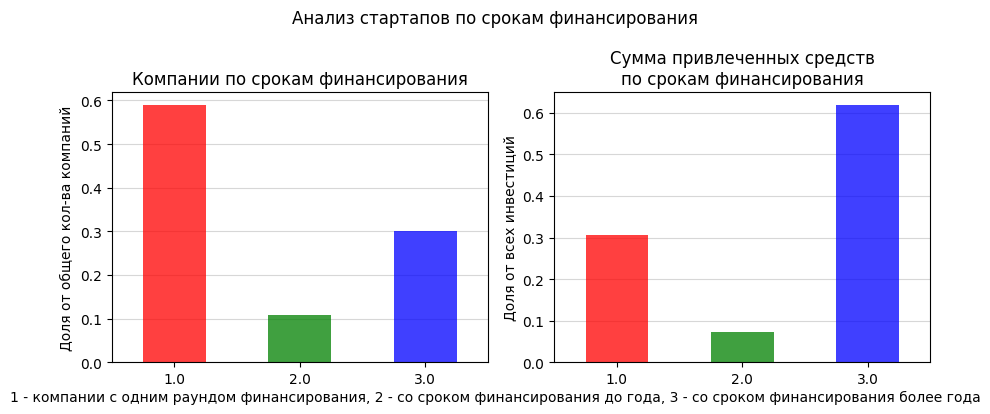

In [59]:
# построим графики для долей компаний и долей привлеченных средств в разных группах компаний по срокам финансирования
funding_rank_colors = ['red', 'green', 'blue']

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

funding_rank_count_share.plot(ax=axes[0], kind='bar',
              color=funding_rank_colors,
              rot=0,
              zorder=2,
             alpha=0.75)

axes[0].grid(alpha=0.5, zorder=0, axis='y')
axes[0].set_xlabel('')
axes[0].set_ylabel('Доля от общего кол-ва компаний')
axes[0].set_title('Компании по срокам финансирования')

funding_rank_money_share.plot(ax=axes[1], kind='bar',
              color=funding_rank_colors,
              rot=0,
              zorder=2,
             alpha=0.75)

# CORRECT: Use axes[1] instead of ax[1]
axes[1].grid(alpha=0.5, zorder=0, axis='y')
axes[1].set_xlabel('')
axes[1].set_ylabel('Доля от всех инвестиций')
axes[1].set_title('Сумма привлеченных средств\nпо срокам финансирования')

fig.suptitle('Анализ стартапов по срокам финансирования')
fig.text(0.5, 0, '1 - компании с одним раундом финансирования, 2 - со сроком финансирования до года, 3 - со cроком финансирования более года', 
         ha='center', fontsize=10)
plt.tight_layout()
plt.show()

Анализ стартапов по срокам финансирования показал:
- Стартапы разделены по группам по срокам финансирования следующим образом: 60% стартапов с одним раундом, 10% стартапов со сроком финансирования до года, 30% со сроком финансирования больше года.
- Суммы привлеченных средств распределены по срокам финансирования следующим образом: 30% средств привлечены в стартапы с одним раундом финансирования, ~7% - в стартапы со сроком финансирования до года, 63% - со сроком финансирования более года.

### 2.2 Выделение средних и нишевых сегментов рынка

Рассчитаем, как часто в датасете встречается каждый из сегментов `market`. Сегменты, к которым относится более 120 компаний, отнесем к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесем к средним, а сегменты до 35 компаний отнесем к нишевым. Рассчитаем, сколько сегментов попадает в каждую из категорий.

Построим график распределения количества компаний.

In [60]:
# Зададим пользовательскую функцию для разделения комапний по категориям сегментов рынка
def market_category(row):
    if row > 120:
        return 'массовый'
    elif row >= 35 and row <= 120:
        return 'средний'
    elif row <35:
        return 'нишевый'
    else: return 'нет группы'

In [61]:
# Сгруппируем данные cb_investments.csv по `market` и подсчитаем количество компаний для каждого семента `market`
markets = investments_df.groupby('market').agg(companies_count=('name', 'count')).sort_values(by='companies_count', ascending=False)

In [62]:
# Создадим вспомогательную таблицу, в которой будет содержаться информация о категории сегмента (массовый, средний, нишевый) для каждого сегмента рынка
market_groups = markets['companies_count'].apply(market_category)
market_groups = market_groups.to_frame('market_group')
market_groups['market_group'] = pd.Categorical(market_groups['market_group'],
                              categories=['нишевый', 'средний', 'массовый'], 
                              ordered=True)

In [63]:
# Объединим таблицы markets и market_groups для дальнейшей визуализации
markets_frame = markets.join(market_groups)

In [64]:
# Сгруппируем данные markets_frame по категориям сегнемтов рынка и подсчитаем долю компаний, приходящуюся на каждую категорию сегмента 
markets_category_count = markets_frame.groupby('market_group').agg(market_category_count=('companies_count', lambda x: x.sum() / investments_df['market'].dropna().count()))

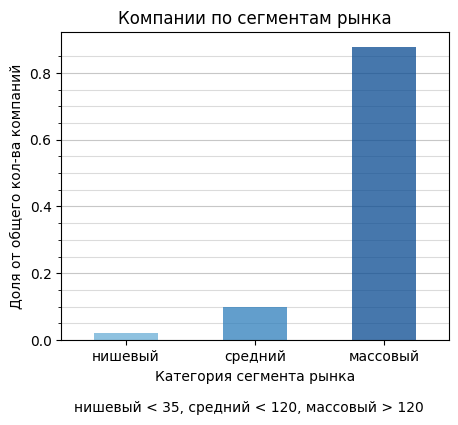

In [65]:
# построим график для долей компаний в разных категориях сегнентов рынка
colors = plt.cm.Blues(np.linspace(0.5, 0.9, len(markets_category_count)))

fig, axes = plt.subplots(figsize=(5, 4))

markets_category_count['market_category_count'].plot(ax=axes, kind='bar',
              color=colors,
              rot=0,
              zorder=2,
             alpha=0.75)

axes.set_yticks(np.arange(0, 0.9, 0.05), minor=True)
axes.set_yticks(np.arange(0, 1, 0.2))
axes.grid(axis='y', which='major', linestyle='-', alpha=0.7)
axes.grid(axis='y', which='minor', linestyle='-', alpha=0.45)
axes.set_xlabel('Категория сегмента рынка')
axes.set_ylabel('Доля от общего кол-ва компаний')
axes.set_title('Компании по сегментам рынка')
fig.text(0.5, -0.07, 'нишевый < 35, средний < 120, массовый > 120', 
         ha='center', fontsize=10)
fig.show()

- Все сегменты рынка поделены на три категории: нишевые сегменты (до 35 компаний в сегменте), средние сегменты (до 120 компаний в сегменте) и массовые сегменты (более 120 компаний в сегменте).
- На долю массовых сегментов приходятся около 87% всех компаний, на долю средних сегментов - около 10% компаний, нишевым сегментам пренадлежат не более 3% сегментов. 

Оставим в столбце `market` только массовые сегменты. Для остальных сегментов заменим значения на заглушки — `niche` для нишевых и `mid` для средних.

Дальнейшие исследования выполним с учётом этой замены.

In [66]:
# зададим пользовательскую функцию для смены значений market в датасебе cb_investments.csv
def market_group_replace(row):
    if row['market_group'] == 'нишевый':
        return 'niche'
    elif row['market_group'] == 'средний':
        return 'mid'
    else:
        return row['market']

In [67]:
# Добавим в датасет на основе cb_investments.csv столбец market_groups, необходимый для замены в market
investments_df = investments_df.merge(market_groups, on='market', how='left')

In [68]:
# произведем замену значений в market
investments_df['market'] = investments_df.apply(market_group_replace, axis=1)

In [69]:
investments_df.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,snake_name,snake_homepage_url,funding_term_rank,market_group
0,Harvard University,http://harvard.edu,|Education|,education,90000000,operating,USA,MA,Boston,Cambridge,1.0,NaN,NaT,NaT,NaT,1636.0,2014-01-06,2014-01-06,2014-01-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,90000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,harvard_university,http://harvard.edu,1.0,массовый
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,2000000,operating,NaN,NaN,NaN,NaN,1.0,NaN,1785-01-01,NaT,NaT,1785.0,2014-05-15,2014-05-15,2014-05-15,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,university_of_new_brunswick,http://www.unb.ca,1.0,NaN
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,mid,9000000,operating,USA,DE,"Wilmington, Delaware",Wilmington,1.0,1.0,1802-07-19,NaT,NaT,1802.0,2009-07-02,2009-07-02,2009-07-02,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,dupont,http://www.dupont.com,1.0,средний
3,University of Michigan,http://www.umich.edu/,|Education|,education,7700000,operating,USA,MI,Detroit,Ann Arbor,3.0,0.0,1817-01-01,NaT,NaT,1817.0,2013-11-21,2013-11-21,2014-11-03,0.0,0.0,0.0,1600000.0,0.0,0.0,0.0,6100000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,university_of_michigan,http://www.umich.edu/,2.0,массовый
4,Case Western Reserve University,http://www.case.edu,|Education|,education,540000,operating,USA,OH,Cleveland,Cleveland,1.0,NaN,1826-01-01,NaT,NaT,1826.0,2014-01-14,2014-01-14,2014-01-14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,540000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,case_western_reserve_university,http://www.case.edu,1.0,массовый


## 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

- По предобработанному столбцу `funding_total_usd` оценим, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся.
- Определим компании с аномальным объёмом общего финансирования. Определим сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведем топ таких сегментов.

In [70]:
# рассчитаем первый и третий квартиль, межквартильный интервал для распределения funding_total_usd и 'усы' для диаграммы размаха funding_total_usd 

q1 = investments_df['funding_total_usd'].quantile(q=0.25)
q3 = investments_df['funding_total_usd'].quantile(q=0.75)
iqr = q3 - q1
l_whisker = q1 - 1.5 * iqr
r_whisker = q3 + 1.5 * iqr

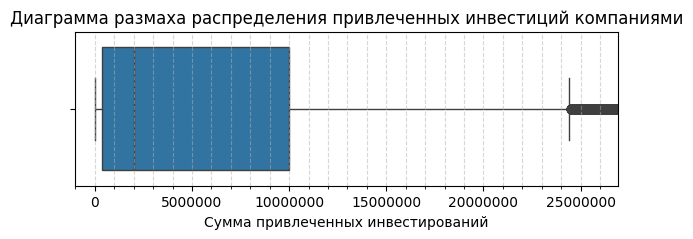

In [71]:
# построим диаграмму размаха для funding_total_usd

fig, ax = plt.subplots(figsize=(7, 2))

# Correct syntax - specify data= and x= as column name
ax = sns.boxplot(data=investments_df,
                 x='funding_total_usd',
                 zorder=0)

plt.xlim(-1000000, r_whisker * 1.1)
ax.xaxis.set_minor_locator(plt.MultipleLocator(1000000))
ax.grid(axis='x', which='both', alpha=0.5, linestyle='--', zorder=2)
plt.gca().ticklabel_format(axis='x', style='plain')
plt.ylabel('')
plt.xlabel('Сумма привлеченных инвестирований')
plt.title('Диаграмма размаха распределения привлеченных инвестиций компаниями')
plt.show()

In [72]:
# Выведем статистику по общим объемам финансирования для компаний
investments_df['funding_total_usd'].describe()

count    4.089600e+04
mean     1.591624e+07
std      1.687013e+08
min      1.000000e+00
25%      3.500000e+05
50%      2.000000e+06
75%      1.000000e+07
max      3.007950e+10
Name: funding_total_usd, dtype: float64

In [73]:
# Сгруппируем данные по сегментам рынка и посчитаем кол-во компаний с аномальным финансированием по сегментам
abnormal_funding = investments_df.loc[investments_df['funding_total_usd'] > r_whisker].groupby('market')['name'].count().sort_values(ascending=False)

In [74]:
print('Топ-5 сегментов рынка с аномальным финансированием по количеству компаний:', end='\n\n')
print(abnormal_funding.head())

Топ-5 сегментов рынка с аномальным финансированием по количеству компаний:

market
biotechnology       828
software            482
mid                 469
clean_technology    326
health_care         320
Name: name, dtype: int64


In [75]:
print(f"Количество компаний с аномальным объемом финансирования: {abnormal_funding.sum()}")

Количество компаний с аномальным объемом финансирования: 5120


Среднее значение объема выделенных средств для компании составляет 1590 млн \\$, медианное значение 2 млн \\$; распределение скошено вправо из-за аномальных значений финансирования.
Сегменты с наибольшим количеством компаний с аномальным финансированием:
1) биотехнологии - 828 компаний
2) программное обеспечение - 482
3) компании средних сегментов - 469
4) числые технологии - 326
5) здравоохранение - 320

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверим по датасету, можно ли считать, предоставлены полные данные за 2014 год. Затем исключим из датасета компании, которые получили аномальное финансирование.

После исключения аномальных записей, на основе столбцов `mid_funding_at` и `funding_rounds` оставим в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

In [76]:
# выведем минимальную и максимальную дату первого финансирования для всех дат первого финансирования в 2014 году
investments_df.loc[(investments_df['first_funding_at'] >= '2014-01-01') & (investments_df['first_funding_at'] <= '2014-12-31')].agg({'first_funding_at': ['min', 'max']})

,first_funding_at
min,2014-01-01
max,2014-12-31


In [77]:
# выведем минимальную и максимальную дату последнего финансирования для всех дат последнего финансирования в 2014 году
investments_df.loc[(investments_df['last_funding_at'] >= '2014-01-01') & (investments_df['last_funding_at'] <= '2014-12-31')].agg({'last_funding_at': ['min', 'max']})

,last_funding_at
min,2014-01-01
max,2014-12-31


In [78]:
investments_df['first_funding_at'].max()

Timestamp('2014-12-31 00:00:00')

Наиболее ранними датами как первого, так и последнего финансирования являются **01.01.2014**. Точно так же для наиболее поздней даты первого и последнего финансирования - **31.12.2014**.

Исключим из датасета стартапы с аномальным финансированием.

In [79]:
investments_df = investments_df.loc[investments_df['funding_total_usd'] < r_whisker]

Исключим из датасета данные о годах с низкой инвестиционной активностью (меньше 50 раундов в году). 

In [80]:
investments_df['mid_funding_at'].dt.year.info()

<class 'pandas.core.series.Series'>
Index: 35664 entries, 1 to 40895
Series name: mid_funding_at
Non-Null Count  Dtype  
--------------  -----  
35663 non-null  float64
dtypes: float64(1)
memory usage: 557.2 KB


In [81]:
# определим года, в которых было больше 50 раундов финансирования
investments_df['mid_funding_year'] = investments_df['mid_funding_at'].dt.year
funding_round_by_year = investments_df.groupby('mid_funding_year')['funding_rounds'].sum()
filtered_years = funding_round_by_year[funding_round_by_year >= 50]
years_rounds_more_50_list = filtered_years.index.tolist()

In [82]:
# Выведем список лет с количеством раундов > 50
print('Список лет с суммарным кол-вом раундов больше 50:', years_rounds_more_50_list, sep='\n')

Список лет с суммарным кол-вом раундов больше 50:
[1999.0, 2000.0, 2001.0, 2002.0, 2003.0, 2004.0, 2005.0, 2006.0, 2007.0, 2008.0, 2009.0, 2010.0, 2011.0, 2012.0, 2013.0, 2014.0]


In [83]:
# Исключим из датасета данные о годах с количеством раундов меньше 50
investments_df = investments_df.loc[investments_df['mid_funding_year'].isin(years_rounds_more_50_list)]

In [84]:
investments_df.shape

(35616, 45)

In [85]:
# Выведем количество строк и столбцов в датасете cb_investments.csv после удаления данных об аномальном финансировании
# и данных о годах с низкой инвестиционной активностью.

print('Кол-во строк и столбцов в датасете cb_investments.csv после удаления данных об', 'аномальном финансировании и данных о годах с низкой инвестиционной активностью:', investments_df.shape, sep='\n')

Кол-во строк и столбцов в датасете cb_investments.csv после удаления данных об
аномальном финансировании и данных о годах с низкой инвестиционной активностью:
(35616, 45)


### 3.3. Анализ типов финансирования по объёму и популярности

Построим график, который покажет, какие типы финансирования в сумме привлекли больше всего денег.

Также построим график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

In [86]:
# Сформируем список названий столбцов с финансированием
funding_col = ['seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding']

In [87]:
# посчитаем распределение привлеченных средств для разных типов финансирования
funding_money = investments_df[funding_col].sum().sort_values()

In [88]:
# создадим вспомагательный датасет с данными о суммах, привлеченных разными видами финансирования
money_return_df = funding_money.reset_index().merge(returns_df.sum().reset_index(), on='index')
money_return_df.set_index('index', inplace=True)
money_return_df.columns = ['funding', 'returns']
money_return_df['returns'] = money_return_df['returns'] * 1e6 
money_return_df['return_share'] = money_return_df['returns'] / money_return_df['funding'] 

In [89]:
# выведем датафрейм с данными о суммах, привлеченных разными выдами финансирования
money_return_df

,funding,returns,return_share
index,,,
secondary_market,4.528580e+07,5.200000e+06,0.114826
post_ipo_debt,1.698091e+08,9.103000e+07,0.536073
product_crowdfunding,2.129356e+08,1.860000e+06,0.008735
equity_crowdfunding,2.787173e+08,3.830000e+06,0.013742
convertible_note,5.004811e+08,3.479000e+07,0.069513
post_ipo_equity,1.097385e+09,1.104960e+09,1.006903
grant,1.900186e+09,0.000000e+00,0.000000
undisclosed,2.311989e+09,7.308800e+08,0.316126
angel,2.642801e+09,1.509230e+09,0.571072


In [90]:
# посчитаем количество раундов финансирования для разных типов финансирования
funding_popularity = investments_df[funding_col].apply(lambda x: x.value_counts().loc[x.value_counts().index != 0].sum(), axis=0) .sort_values()

In [91]:
# Создадим множество типов финансирования
all_categories = set(funding_money.index.tolist()) 
all_categories = all_categories.union(set(money_return_df.index.tolist()))

# Создадим набор цветов с числом цветов, равным кол-ву типов финансирования 
colors = list(mcolors.TABLEAU_COLORS.values())
if len(all_categories) > len(colors):
    additional_colors = list(mcolors.BASE_COLORS.values()) + list(mcolors.CSS4_COLORS.values())
    colors.extend(additional_colors)

# создадим общий словарь с цветами для всех типов финансирования
category_color_dict = dict(zip(all_categories, colors[:len(all_categories)]))

# Создадим списки с цветами для каждого типа визуализации
colors1 = [category_color_dict[cat] for cat in funding_money.index]
colors2 = [category_color_dict[cat] for cat in funding_money.index]
colors3 = [category_color_dict[cat] for cat in money_return_df['returns'].sort_values().index]
colors4 = [category_color_dict[cat] for cat in money_return_df['return_share'].sort_values().index]
colors5 = [category_color_dict[cat] for cat in (funding_popularity).index]

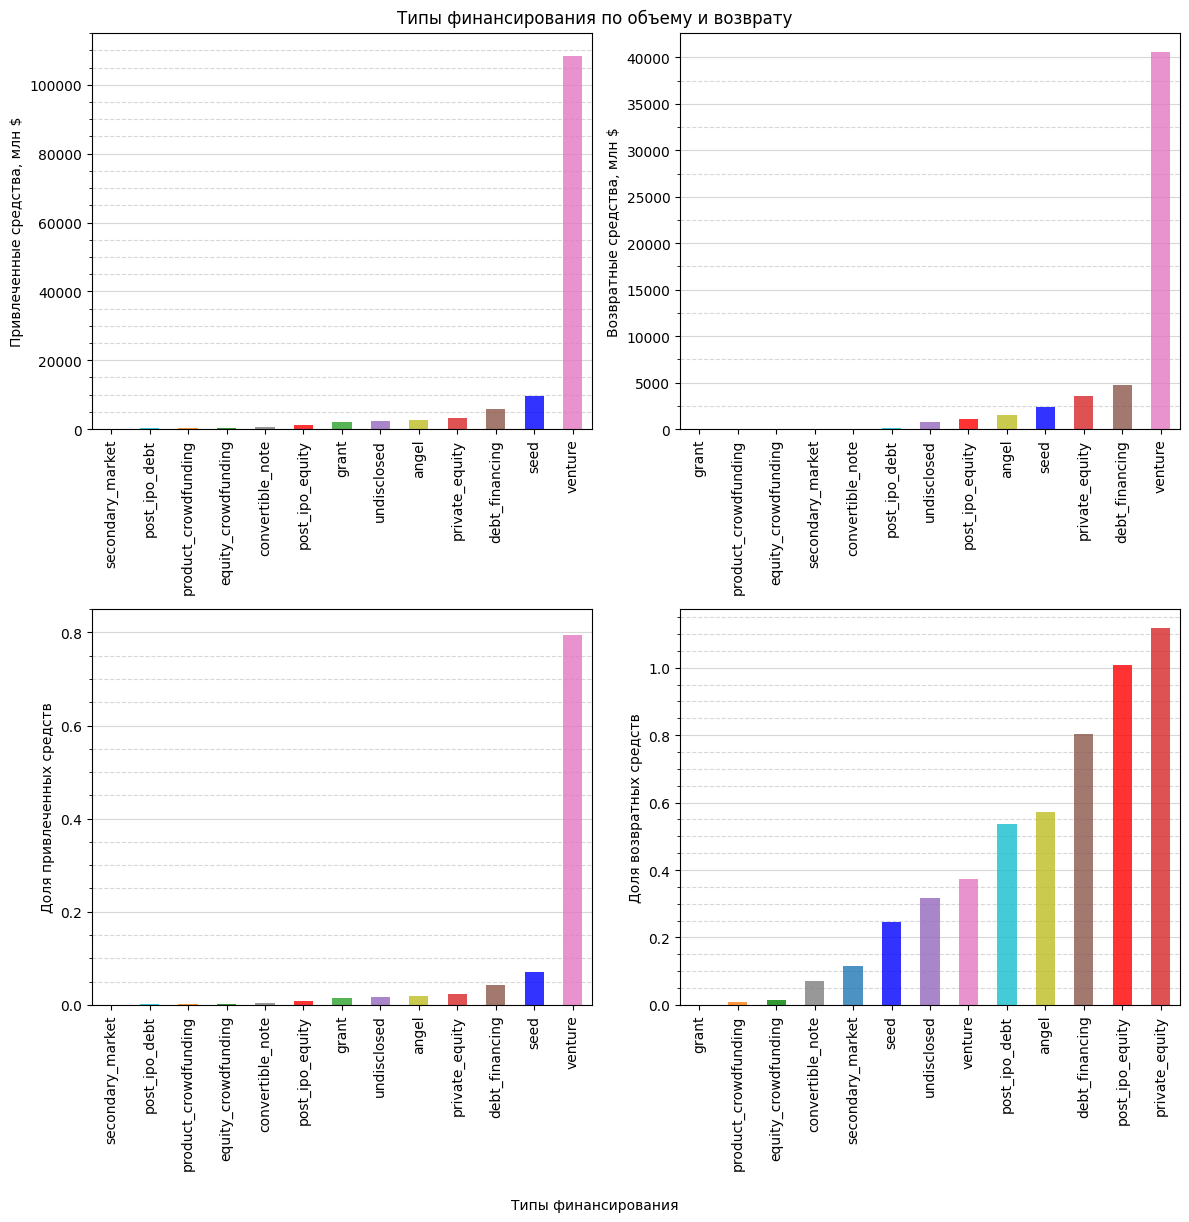

In [92]:
# построим график доли привлеченных стредств, доли возвратных средств и кол-ва раундов финансирования для разных типов финансирования 
fig, axes = plt.subplots(2,2, figsize=(12,12))
                           
(funding_money / 1000000).plot(kind='bar', ax=axes[0, 0], zorder=2, alpha=0.8, color=colors1)
axes[0, 0].set_ylabel('Привлеченные средства, млн $')
axes[0, 0].grid(axis='y', alpha=0.5)
axes[0, 0].set_yticks(np.arange(0, 120000, 5000), minor=True)
axes[0, 0].ticklabel_format(style='plain', axis='y')
axes[0, 0].grid(axis='y', which='minor', linestyle='--', alpha=0.5)

(funding_money / funding_money.sum()).plot(kind='bar', ax=axes[1, 0], zorder=2, alpha=0.8, color=colors2)
axes[1, 0].set_ylabel('Доля привлеченных средств')
axes[1, 0].grid(axis='y', alpha=0.5)
axes[1, 0].set_yticks(np.arange(0, 0.9, 0.2))
axes[1, 0].set_yticks(np.arange(0, 0.9, 0.05), minor=True)
axes[0, 0].ticklabel_format(style='plain', axis='y')
axes[1, 0].grid(axis='y', which='minor', linestyle='--', alpha=0.5)

(money_return_df['returns'].sort_values() / 1000000).plot(kind='bar', ax=axes[0, 1], zorder=2, alpha=0.8, color=colors3)
axes[0, 1].set_ylabel('Возвратные средства, млн $')
axes[0, 1].set_xlabel('')
axes[0, 1].grid(axis='y', alpha=0.5)
axes[0, 1].set_yticks(np.arange(0, 42500, 2500), minor=True)
axes[0, 1].grid(axis='y', which='minor', linestyle='--', alpha=0.5)

(money_return_df['return_share'].sort_values()).plot(kind='bar', ax=axes[1, 1], zorder=2, alpha=0.8, color=colors4)
axes[1, 1].set_ylabel('Доля возвратных средств')
axes[1, 1].set_xlabel('')
axes[1, 1].grid(axis='y', alpha=0.5)
axes[1, 1].set_yticks(np.arange(0, 1.2, 0.05), minor=True)
axes[1, 1].grid(axis='y', which='minor', linestyle='--', alpha=0.5)

plt.suptitle('Типы финансирования по объему и возврату')
fig.text(0.5, -0.02, 'Типы финансирования', 
         ha='center', fontsize=10)
plt.tight_layout()

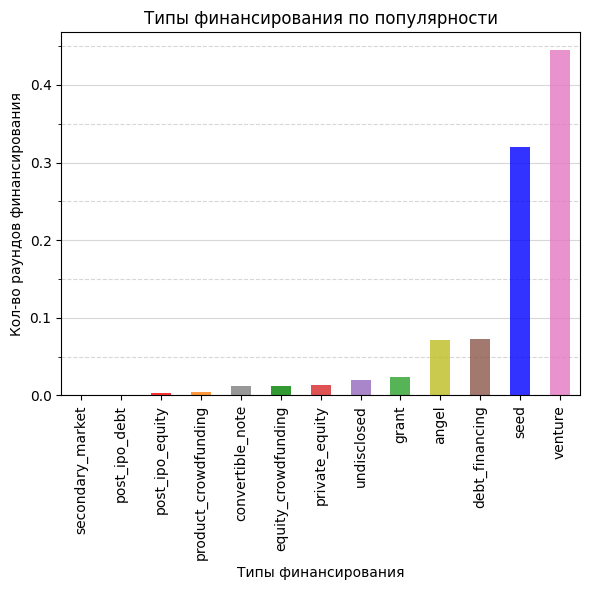

In [93]:
fig, axes = plt.subplots(figsize=(6,6))

(funding_popularity / funding_popularity.sum()).plot(kind='bar', ax=axes, zorder=2, alpha=0.8, color=colors5)
axes.set_ylabel('Кол-во раундов финансирования')
axes.set_xlabel('Типы финансирования')
axes.grid(axis='y', alpha=0.5)
axes.set_yticks(np.arange(0, 0.5, 0.05), minor=True)
axes.grid(axis='y', which='minor', linestyle='--', alpha=0.5)

plt.title('Типы финансирования по популярности')
plt.tight_layout()

Типы финансирования, привлекшие больше всего средств, в процентах от общего объема привлеченных средств:
1) венчурные инвестиции ~ 80%
2) посевные ивестиции ~ 7.5%
3) долговое финансирование ~ 5%
4) прямые вложения ~ 2.5%
5) вложения от бизнес-ангелов ~ 2%
  
При этом раунды финансирования распределены по типам финансирвания следующим образом:
1) венчурные инвестиции ~ 45%
2) посевные инвестиции ~ 32%
3) долговое финансирование ~ 7%
4) финансирование от бизнес-ангелов ~ 7%
6) гранты ~ 2.5%

Возврат средств показал, что есть типы финасирования с аномальными значениями возврата, превышающие объем вложения.

Таким образом, самым востребованным типом инвестирования является венчурное финансирование - на него приходится 80% всех привлеченных средств и 45% всех проведенных раундов финансирвания за исследуемый период. На долю посевных инвестиций приходится чуть больше 7% привлеченных средств, при этом на этот тип финансирования приходится 32% всех раундов финансирования.

## 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам

Рассчитаем для каждой компании средний объём одного раунда финансирования.

На основе получившейся таблицы постройте графики, отражающие:
* динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования;

* динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

In [94]:
# рассчитаем привлеченное финансирование по годам
funding_year = investments_df.groupby('mid_funding_year')['funding_total_usd'].sum().reset_index()

In [95]:
# рассчитаем среднее кол-во раундов финансирования на одну компанию по годам
avg_rounds_year = investments_df.groupby('mid_funding_year')['funding_rounds'].mean().reset_index()

In [96]:
# рассчитаем средний размер финансирования одного раунда каждой компании
investments_df['average_round_funding'] = investments_df['funding_total_usd'] / investments_df['funding_rounds']

In [97]:
# сгруппируем данные по годам финансирования и рассчитаем среднее значение финансирования одного раунда по годам
avr_round_funding_year = investments_df.groupby('mid_funding_year')['average_round_funding'].mean().reset_index()

In [98]:
# рассчитаем суммарное кол-во раундов финансирования по годам
count_round_funding_year = investments_df.groupby('mid_funding_year')['funding_rounds'].sum().reset_index()

In [99]:
for df in [funding_year, avg_rounds_year, avr_round_funding_year, count_round_funding_year]:
    df['mid_funding_year'] = pd.to_numeric(df['mid_funding_year'], downcast='integer')

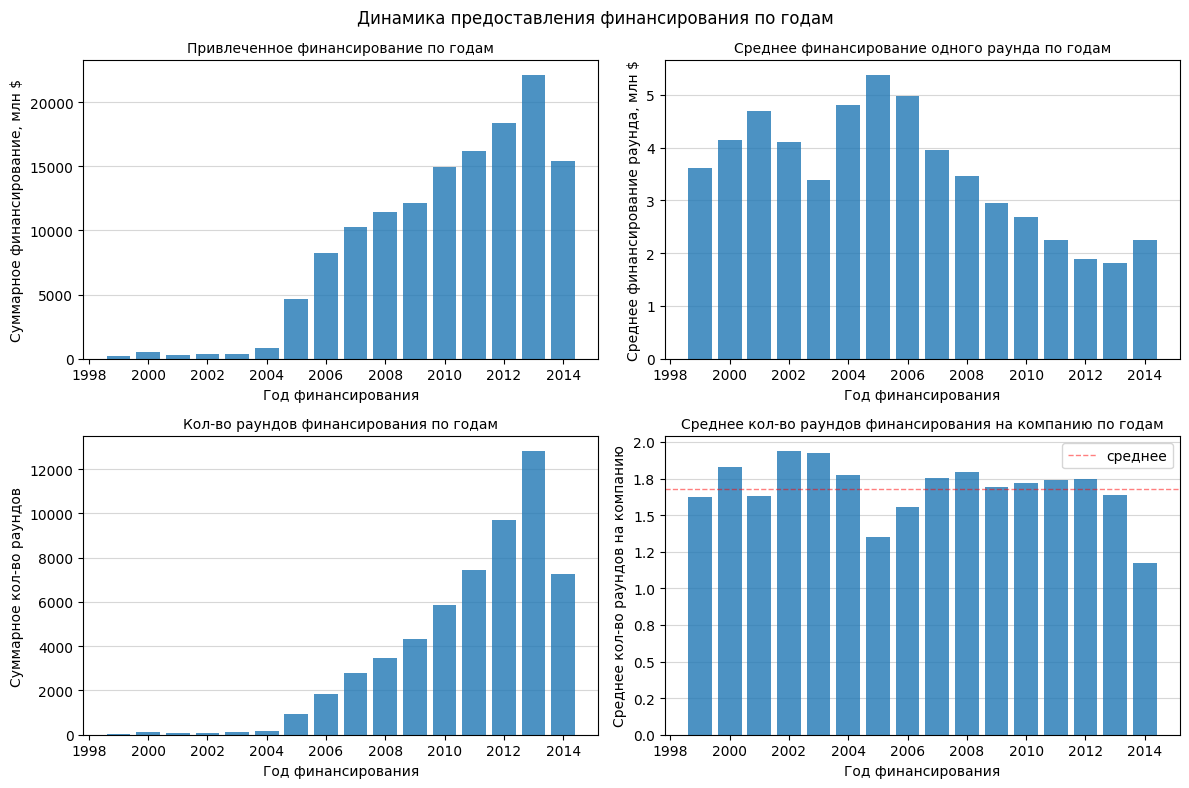

In [100]:
# построим графики, отражающие динамику финансирования по годам
fig, axes = plt.subplots(2, 2, figsize=(12,8))

plt.rcParams["axes.titlesize"] = 10

#график среднего финансирования одного раунда по годам
axes[0, 0].bar(funding_year['mid_funding_year'],
               funding_year['funding_total_usd'] / 1000000,
               zorder=2,
               alpha=0.8)

axes[0, 0].grid(axis='y', alpha=0.5)
plt.gca().ticklabel_format(axis='y', style='plain')

axes[0, 0].set_xlabel('Год финансирования')
axes[0, 0].set_ylabel('Суммарное финансирование, млн $')

axes[0, 0].set_title('Привлеченное финансирование по годам')

#график среднего финансирования одного раунда по годам
axes[0, 1].bar(avr_round_funding_year['mid_funding_year'],
                avr_round_funding_year['average_round_funding'] / 1000000,
                zorder=2,
                alpha=0.8)

axes[0, 1].grid(axis='y', alpha=0.5)
plt.gca().ticklabel_format(axis='y', style='plain')

axes[0, 1].set_xlabel('Год финансирования')
axes[0, 1].set_ylabel('Среднее финансирование раунда, млн $')

axes[0, 1].set_title('Cреднее финансирование одного раунда по годам')

#график суммарного кол-ва раундов финансирования по годам
axes[1, 0].bar(count_round_funding_year['mid_funding_year'],
               count_round_funding_year['funding_rounds'],
               zorder=2,
               alpha=0.8)

axes[1, 0].grid(axis='y', alpha=0.5)

axes[1, 0].set_xlabel('Год финансирования')
axes[1, 0].set_ylabel('Суммарное кол-во раундов')

axes[1, 0].set_title('Кол-во раундов финансирования по годам')

#график среднего кол-ва раундов финансирования на компанию по годам
axes[1, 1].bar(avg_rounds_year['mid_funding_year'],
               avg_rounds_year['funding_rounds'],
               zorder=2,
               alpha=0.8)

axes[1, 1].grid(axis='y', alpha=0.5)

axes[1, 1].set_xlabel('Год финансирования')
axes[1, 1].set_ylabel('Среднее кол-во раундов на компанию')

axes[1, 1].set_title('Среднее кол-во раундов финансирования на компанию по годам')

formatter = FormatStrFormatter('%.1f')
axes[1, 1].yaxis.set_major_formatter(formatter)

axes[1, 1].axhline(y=avg_rounds_year['funding_rounds'].mean(),
                   color='red',
                   linestyle='--',
                   linewidth=1,
                   alpha=0.5,
                   label='среднее')
axes[1, 1].legend()

fig.suptitle('Динамика предоставления финансирования по годам')
plt.tight_layout()
plt.show()

Анализ динамики финансирования по годам показал:
- Общее финансирование по годам монотонно растет с 2004 по 2013 годы, после чего наблюдается спад в 2014 году. Наибольший размер среднего финансирования одного раунда наблюдается в 2006 году, после чего размер среднего финансирования раунда падает вплоть до 2013 года. В 2014 среднее финанирование раунда выше, чем в 2013.
- Суммарное кол-во раундов, как и общее финансирование, монотонно растет с 2004 по 2013 годы, после чего падает в 2014. При этом среднее кол-во раундов на компанию практически не меняется и колеблется возле значения 1.7.

Общий тренд: суммарно cтартапы привлекают больше средств за счет роста количества стартапов, при этом среднее финансирование одного раунда падает - инвесторы чаще финансируют небольшие стартапы. Наблюдается слом тренда в 2014 году: инвесторы стали реже финансировать стартапы, при этом стали выделять больше денег на один раунд.

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составим сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Далее отберем из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

На графике отразим, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у вас достаточно данных, при этом рассматривать будем только массовые сегменты.

На основе графика сделаем вывод о том, какие сегменты показывают наиболее быстрый и уверенный рост.

In [101]:
mass_market = investments_df.loc[(investments_df['market'] != 'mid') & (investments_df['market'] != 'niche')]

market_years_funding = pd.pivot_table(mass_market,
                                      values='funding_total_usd',
                                      index='market',
                                      columns='mid_funding_year') / 1000000

market_years_funding.columns = market_years_funding.columns.astype('int')
market_years_funding = market_years_funding.round(decimals=1) 

In [102]:
print('\033[1mСводная таблица общего финансирования  по годам и сегментам рынка, млн $\033[0m')
market_years_funding.style.background_gradient(cmap='Blues').format('{:.1f}')

Сводная таблица общего финансирования  по годам и сегментам рынка, млн $


mid_funding_year,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
market,,,,,,,,,,,,,,,,
advertising,0.4,4.8,8.8,12.2,10.5,6.0,9.2,6.0,7.9,6.8,5.6,5.3,2.7,3.2,2.9,2.1
analytics,10.8,7.4,nan,7.5,3.8,3.0,7.2,7.8,5.4,6.0,4.9,4.4,5.4,4.4,3.8,2.1
apps,nan,nan,nan,nan,nan,nan,nan,1.3,20.2,5.4,6.6,5.7,1.4,2.4,1.8,1.5
automotive,nan,nan,nan,nan,4.5,nan,22.5,4.2,9.4,6.6,3.5,2.9,5.9,1.9,3.0,2.2
big_data,nan,nan,nan,nan,nan,nan,nan,nan,2.6,0.8,0.6,9.5,3.4,5.7,3.0,2.6
biotechnology,nan,nan,nan,nan,21.0,11.3,5.7,7.2,7.4,8.6,6.3,5.2,5.3,5.4,5.2,5.7
clean_technology,nan,nan,nan,nan,2.2,19.4,6.5,6.5,8.2,7.7,7.0,5.4,6.6,5.4,4.4,3.2
cloud_computing,nan,11.5,nan,nan,nan,nan,nan,3.3,6.8,5.5,8.7,1.2,3.0,2.9,3.0,3.5
consulting,0.1,4.5,nan,nan,nan,nan,5.0,5.7,4.5,1.7,3.8,2.9,4.4,3.7,2.5,1.7


In [103]:
#Создадим столбец rising_2014, показывающий, рос ли объем инвестиций сегмента в 2014 году относительно 2013
market_years_funding['rising_2014'] = market_years_funding.iloc[:, -1] > market_years_funding.iloc[:, -2]

# создадим вспомагателный датасет с сегментами, показавшими рост в 2014 году относительно 2013
rising_market_years_funding = market_years_funding.loc[
    market_years_funding.index.isin(
        market_years_funding.loc[
            market_years_funding['rising_2014'] == True
        ].index.tolist()
    )
]

In [104]:
# посчитаем общий объем инвестиций в сегментах, показавщих рост в 2014 году относительно 2013
rising_market_years_funding['sum'] = rising_market_years_funding.iloc[:, :-1].sum(axis=1)
rising_market_years_funding.sort_values(by='sum', inplace=True)

In [105]:
# рассчитаем процент роста инвестиций 2014 года к 2013 в ростущих сегментах 
rising_market_years_funding['rise_2014_percent'] = 100 * (rising_market_years_funding.loc[:, 2014] - rising_market_years_funding.loc[:, 2013] / rising_market_years_funding.loc[:, 2013])

In [106]:
# Создадим множество сегментов финансирования
all_categories = set(rising_market_years_funding.index.tolist()) 

# Создадим набор цветов с числом цветов, равным кол-ву сегментов финансирования 
colors = list(mcolors.TABLEAU_COLORS.values())
if len(all_categories) > len(colors):
    additional_colors = list(mcolors.BASE_COLORS.values()) + list(mcolors.CSS4_COLORS.values())
    colors.extend(additional_colors)

# создадим общий словарь с цветами для всех сегментов финансирования
category_color_dict = dict(zip(all_categories, colors[:len(all_categories)]))

# Создадим списки с цветами для каждого типа визуализации
colors1 = [category_color_dict[cat] for cat in rising_market_years_funding['sum'].index]
colors2 = [category_color_dict[cat] for cat in rising_market_years_funding['rise_2014_percent'].sort_values().index]

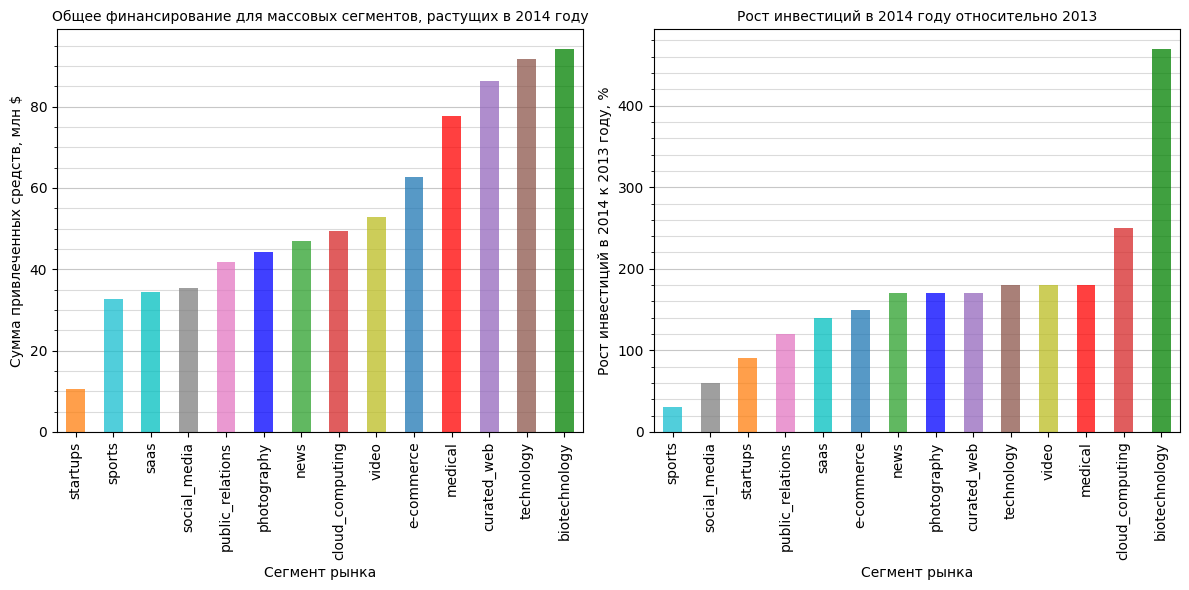

In [107]:
# построим график с общим инвестированием в массовые сегменты, растущие в 2014 году, и с  объемом роста инвестиций 2014 года к 2013 в ростущих сегментах 
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

rising_market_years_funding['sum'].plot(kind='bar', ax=axes[0], color=colors1,
              zorder=2,
             alpha=0.75)

axes[0].set_yticks(np.arange(0, 100, 5), minor=True)
axes[0].grid(axis='y', which='major', linestyle='-', alpha=0.7)
axes[0].grid(axis='y', which='minor', linestyle='-', alpha=0.45)
axes[0].set_xlabel('Cегмент рынка')
axes[0].set_ylabel('Сумма привлеченных средств, млн $')
axes[0].set_title('Общее финансирование для массовых сегментов, растущих в 2014 году')

rising_market_years_funding['rise_2014_percent'].sort_values().plot(kind='bar', ax=axes[1], color=colors2,
              zorder=2,
             alpha=0.75)

axes[1].set_yticks(np.arange(0, 500, 20), minor=True)
axes[1].grid(axis='y', which='major', linestyle='-', alpha=0.7)
axes[1].grid(axis='y', which='minor', linestyle='-', alpha=0.45)
axes[1].set_xlabel('Cегмент рынка')
axes[1].set_ylabel('Рост инвестиций в 2014 к 2013 году, %')
axes[1].set_title('Рост инвестиций в 2014 году относительно 2013')

plt.tight_layout()
fig.show()

Для сегментов , показавщих рост объема вложений в 2014 году, самыми большими по общему объему привлеченных средств являются:
- Биотехнологии - 95 млн \$,
- Технологии - 92 млн \$,
- Игры - 91 млн \$,
- Программное обеспечение - 87 млн \$,
- Web сервисы - 86 млн \$,
- Медицина - 77 млн \$.

Аномальный рост в 2014 году показал сегмент биотехнологий - более 460%, на втором месте облачные решения - 250%, далее следуют сегменты технологии, видео, медицина и сми - 180%. Наименьший рост из растущих сегментов показал сегмент спорта - 30%.

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

Для каждого года и каждого вида финансирования рассчитаем нормированные значения возврата средств. Выбросы заменим на пропуски.

In [108]:
# создадим вспомагательный датасет с группировкой данных по годам инвестирования и рассчетом сумм инвестирования по всем типам вложений
funding_types_year = investments_df.groupby('mid_funding_year')[funding_col].sum()

In [109]:
# Рассчитаем нормированные значения возвратных средств
returns_share = 1e6 * returns_df / (funding_types_year.iloc[1:] + 1e-60)

# Отбросим значения больше 1 - сумма возврата не должна быть выше суммы вложений
returns_share[(returns_share > 1)] = None

In [110]:
return_types_list = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']

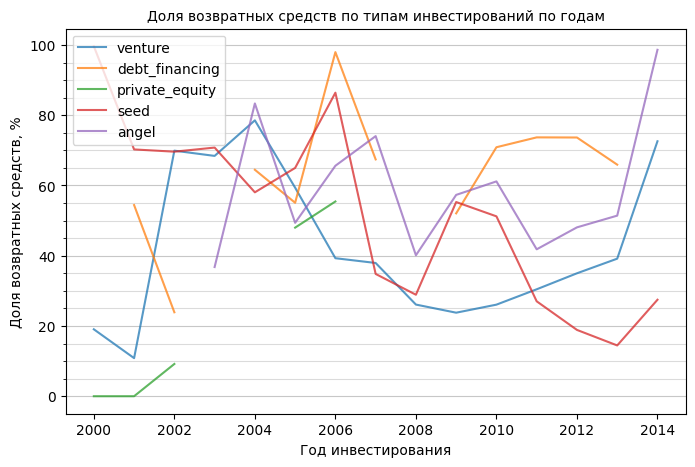

In [111]:
fig, axes = plt.subplots(figsize=(8, 5))

(returns_share[return_types_list] * 100).plot(kind='line', ax=axes,
              zorder=2,
             alpha=0.75)

axes.set_yticks(np.arange(0, 100, 5), minor=True)
axes.grid(axis='y', which='major', linestyle='-', alpha=0.7)
axes.grid(axis='y', which='minor', linestyle='-', alpha=0.45)
axes.set_xlabel('Год инвестирования')
axes.set_ylabel('Доля возвратных средств, %')
axes.set_title('Доля возвратных средств по типам инвестирований по годам')

plt.show()

Для посевных инвестиций доля возвратных средств с годами снижается. Доля вложений от бизнес-ангелов и венчурных инвестиций наблюдается резкий рост возвратов в 2014 году.


## 5. Итоговый вывод и рекомендации

**Общий вывод исследования**

Проведен исследовательский анализ стартапов на основе исторических данных о финансировании стартапов по всему миру до 2014 года включительно и о возврате финансирования. Были предоставлены данные в двух таблицах `cb_investments.csv` и `cb_returns.csv` с подробным описанием содержания таблиц. Первичный анализ данных позволил дать рекомендации по преобразованию типов данных и названий столбцов для оптимизации памяти и упрощения работы с данными, что было выполнено в ходе предобработки. Так же в ходе предобработки были проведены удаление явных и неявных дубликатов, замена пропусков на усредненные значения там, где это возможно, и удаление полностью пустых строк. В результате предобработки количество строк в датасете уменьшилось с 54293 до 40 895, или на 25%.
___
После предобработки был проведен инжиниринг признаков, в ходе которого компании были разделены на группы по срокам финансирования, а так же для сегментов рынка выделены категории по количеству компаний.<br><br>
По срокам финансирования компании были поделены на три группы:
1) Единичное финансирование — был всего один раунд финансирования,
2) cрок финансирования до года — между первым и последним раундом финансирования прошло не более года,
3) cрок финансирования более года.

В 60% компаний был проведен один раунд финансирования, в 10% компаний финансирование длилось не более года, и в 30% компаний срок финансирования был больше года. Суммы привлеченных средств распределены по срокам финансирования следующим образом: 30% средств привлечены в стартапы с одним раундом финансирования, ~7% - в стартапы со сроком финансирования до года, 63% - со сроком финансирования более года.<br><br>
Сегменты разделены на три категории по количеству компаний:
1) на доли массовых сегментов, к которым относится более 120 компаний, приходится 87% компаний;
2) на средние сегменты, в которые входит от 35 до 120 включительно, приходится 10% компаний;
3) на нишевые, в которые входит до 35 компаний - 3% компаний.
___
Были проанализированы аномальные значения финансирования. Среднее значение финансирования компании составило 1590 млн \\$, в то время как медианное значение - отделяющее 50\% компаний, получивших финансирование больше этого значения - 2 млн \\$. Различие среднего и медианного значения говорит о том, распределение финансирования скошено в сторону аномально высокого финансирования.<br><br>
Сегменты с наибольшим количеством компаний с аномальным финансированием:
1) биотехнологии - 828 компаний,
2) программное обеспечение - 482 компании,
3) компании средних сегментов - 469 компаний,
4) числые технологии - 326 компаний,
5) здравоохранение - 320 компаний.

Аномальные значения финансирования были отброшены из датасета, а так же данные о годах с низкой инвестиционной активностью - общим количеством раундов меньше 50 в году.<br><br>
Были проанализированы типы инвестирования по объему привлеченных средств и по частоте использования.
- Венчурное финансирование - самый востребованный тип инвестирования - 80% всех привлеченных средств и 45% всех проведенных раундов финансирвания.
- Посевные инвестиции - чуть больше 7% привлеченных средств, при этом на этот тип финансирования приходится 32% всех раундов финансирования.
___
Проанализирована динамика инвестирования по годам.<br>
Суммарно cтартапы привлекают больше средств за счет роста количества стартапов, при этом среднее финансирование одного раунда падает - инвесторы чаще финансируют небольшие стартапы.<br>
Наблюдается слом тренда в 2014 году: инвесторы стали реже финансировать стартапы, при этом стали выделять больше денег на один раунд. Отдельно проанализирована динамика инвестирования для массовых сегментов, показавших рост в 2014 году:
- Биотехнологии - аномальный рост более 460%,
- Облачные решения - рост 250%,
- Cегменты технологии, видео, медицина и сми - по 180%.

Наименьший рост из растущих сегментов показал сегмент спорта - 30%.<br><br>
Была проанализирована годовая динамика доли возвращённых средств по типам финансирования. Для посевных инвестиций доля возвратных средств с годами снижается. Доля вложений от бизнес-ангелов и венчурных инвестиций наблюдается резкий рост возвратов в 2014 году.<br><br>
**Рекомендации**<br>

Наиболее популярный тип инвестирования на конец 2014 года - венчурное инвестирование. Растущие массовые рынки в 2014 году - биотехнологии, технологии, игры, программное обеспечение, web сервисы, медицина. С учетом того, что количество стартапов растет, и объем финансирования на один раунд финансирования падает, лучше не вкладывать больших средств в один стартап, а разбить их по нескольким.